In [1]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

library(mixOmics)
library(BiocParallel)

Loading required package: MASS

Loading required package: lattice

Loading required package: ggplot2


Loaded mixOmics 6.26.0
Thank you for using mixOmics!
Tutorials: http://mixomics.org
Bookdown vignette: https://mixomicsteam.github.io/Bookdown
Questions, issues: Follow the prompts at http://mixomics.org/contact-us
Cite us:  citation('mixOmics')




In [18]:
DATA_DIR <- "/home/mariya/Data/pallas/mlomix_datasets"

TRAIN_DATA_DIR <- file.path(DATA_DIR, "labeled-diagnostic-bimodal-reduced")
METH_FILE <- file.path(TRAIN_DATA_DIR, "features.dnam.csv")
GEX_FILE <- file.path(TRAIN_DATA_DIR, "features.gex.csv")
LABELS_FILE <- file.path(TRAIN_DATA_DIR, "labels.csv")

MIXOMICS_DIR <- file.path("/home/mariya/Data/pallas/mixOmics")
OUTPUT_DIR <- file.path("/home/mariya/Data/pallas/mixOmics/models_20260809")

# Create output directory if it doesn't exist
if (!dir.exists(OUTPUT_DIR)) {
    dir.create(OUTPUT_DIR, recursive = TRUE)
}

In [19]:
source("helpers.R")
train_data <- data(GEX_FILE, METH_FILE, LABELS_FILE)

Samples: 1227 
GEX features: 1121 
DNAm features: 1186 
Subtypes: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, ETV6-r AML, KAT6A-r AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, BCR::ABL1-like B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, MEF2D-r B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


In [20]:
X.gex <- train_data$X_gex
X.dnam <- train_data$X_dnam
Y     <- train_data$Y

head(X.gex)
head(X.dnam)
head(Y)

,ENSG00000184507,ENSG00000079102,ENSG00000248329,ENSG00000101115,ENSG00000172752,ENSG00000097007,ENSG00000132185,ENSG00000167880,ENSG00000177469,ENSG00000188064,⋯,ENSG00000170396,ENSG00000130702,ENSG00000187325,ENSG00000169213,ENSG00000186980,ENSG00000182747,ENSG00000144681,ENSG00000072954,ENSG00000181007,ENSG00000107819
ALL_1000,-1.608643,-1.608643,15.995107,4.8418488,-1.4407131,6.202016,-0.8269021,0.3324897,1.0468822,-1.306680,⋯,-0.2482395,1.155457,6.090830,-1.60864328,-1.608643,-1.6086433,-1.269090,0.7956456,2.456942,6.361923
ALL_1003,7.866846,-1.608643,-1.608643,-0.1704226,-1.6086433,6.221609,-1.6086433,-0.5538530,-0.7979199,-1.373961,⋯,-1.6086433,-1.147371,4.677110,0.26710648,-1.608643,-1.1408426,-1.608643,-1.2343983,3.309382,5.515478
ALL_1005,-1.608643,-1.608643,-1.608643,3.0300396,-1.5171299,5.962302,5.6071701,0.6443205,-0.6988636,-1.608643,⋯,-1.6086433,1.857859,6.355210,-0.24149963,-1.608643,-1.6086433,3.743243,3.2675844,3.515856,4.569093
ALL_1019,-1.608643,-1.608643,-1.608643,7.0165835,-1.6086433,5.654076,1.5010946,3.2958788,-0.2369391,-1.608643,⋯,-1.6086433,1.988980,5.567993,0.44466570,-1.608643,-1.6086433,-1.161472,3.8516648,2.002225,5.698553
ALL_1023,6.295659,-1.608643,-1.608643,4.0362302,-0.4718155,6.586559,-1.0246909,5.4514953,2.5433950,-1.608643,⋯,0.2861806,-0.133622,4.903089,1.57325962,-1.608643,-0.8427656,-1.364855,0.2819973,2.888247,4.372993
ALL_1026,-1.384271,-1.608643,7.200832,-0.3788483,-1.6086433,6.458333,0.3933072,7.1349388,-0.9366025,7.595660,⋯,-1.6086433,2.223308,5.783929,0.09725186,-1.608643,-1.6086433,-1.608643,1.1623027,2.910556,5.311609


,cg10443049,cg07275648,cg00760938,cg04646674,cg12183594,cg03732020,cg14992144,cg13799263,cg08166720,cg00015639,⋯,cg01955153,cg26092233,cg18631798,cg21927946,cg11551919,cg01883662,cg20294319,cg12737392,cg09291834,cg11414821
ALL_1000,0.8325,0.9452,0.0400,0.9366,0.9854,0.7879,0.0186,0.9181,0.9419,0.2988,⋯,0.1614,0.0677,0.0333,0.2134,0.9773,0.9641,0.0702,0.0862,0.8104,0.0315
ALL_1003,0.9219,0.6754,0.1550,0.9236,0.9849,0.9087,0.0272,0.7213,0.9059,0.7597,⋯,0.0889,0.1056,0.0643,0.7567,0.9731,0.9196,0.0946,0.0913,0.0193,0.0256
ALL_1005,0.9113,0.9435,0.0375,0.6264,0.9850,0.9844,0.0230,0.7807,0.9334,0.9095,⋯,0.2638,0.0489,0.0296,0.0678,0.9645,0.9251,0.0899,0.1216,0.4870,0.0326
ALL_1019,0.7243,0.9433,0.0757,0.9088,0.9829,0.9830,0.0267,0.8941,0.4691,0.6096,⋯,0.1940,0.0529,0.0354,0.0220,0.3327,0.1337,0.0656,0.0774,0.1054,0.0233
ALL_1023,0.8656,0.9308,0.1669,0.8532,0.9857,0.8091,0.0480,0.9283,0.9532,0.8493,⋯,0.2563,0.1559,0.0972,0.0441,0.9504,0.9194,0.0604,0.1027,0.1858,0.0363
ALL_1026,0.9320,0.6853,0.0826,0.8681,0.9848,0.9876,0.0354,0.9055,0.9592,0.7046,⋯,0.1624,0.1184,0.0643,0.0251,0.3294,0.1498,0.0533,0.0888,0.0324,0.0294


[1] B-ALL, DUX4-r      B-ALL, PAX5alt     B-ALL, MEF2D-r     B-ALL, ZNF384-r   
[5] B-ALL, ETV6::RUNX1 B-ALL, PAX5alt    
25 Levels: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 ... T-ALL

In [ ]:
NCOMP <- 35
KEEP_X <- 100

keepX.gex <- rep(KEEP_X, NCOMP)
keepX.dnam <- rep(KEEP_X, NCOMP)

NCOMP
keepX.gex
keepX.dnam

[1] 35

[1] 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100
[20] 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100

[1] 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100
[20] 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100

In [8]:
# Single block models
model.gex   <- splsda(X.gex, Y, ncomp = NCOMP, keepX = keepX.gex)
model.dnam  <- splsda(X.dnam, Y, ncomp = NCOMP, keepX = keepX.dnam)

In [23]:
# build blocks as lists (so names(X) works)
X <- list(gex = X.gex, dnam = X.dnam)
keepX <- list(gex = keepX.gex / 2, dnam = keepX.dnam / 2)  # divide by 2 to keep total features same as single block models

# Integrated model (design favors discrimination)
design.int <- matrix(0.1, ncol = 2, nrow = 2, dimnames = list(names(X), names(X)))
diag(design.int) <- 0
model.integrated <- block.splsda(X, Y, ncomp = NCOMP, keepX = keepX, design = design.int)

model.integrated

Design matrix has changed to include Y; each block will be
            linked to Y.



Warning message:
“The SGCCA algorithm did not converge”



Call:
 block.splsda(X = X, Y = Y, ncomp = NCOMP, keepX = keepX, design = design.int) 

 sGCCA with 35 components on block 1 named gex 
 sGCCA with 35 components on block 2 named dnam 
 sGCCA with 35 components on the outcome Y

 Dimension of block 1 is  1227 1121 
 Dimension of block 2 is  1227 1186 
 Outcome Y has 25 levels 

 Selection of 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 variables on each of the sGCCA components on the block 1 
 Selection of 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 50 variables on each of the sGCCA components on the block 2 

 Main numerical outputs: 
 -------------------- 
 loading vectors: see object$loadings 
 variates: see object$variates 
 variable names: see object$names 

 Functions to visualise samples: 
 -------------------- 
 plotIndiv, plotArrow, cimDiablo, plotDiablo 

 Functions to visualise variables: 
 ------------------

In [10]:
N_FOLDS <- 5
N_REPEATS <- 50
DIST <- "centroids.dist"


In [ ]:

# Compare via CV
perf.gex    <- perf(
    model.gex,
    validation = "Mfold",
    folds = N_FOLDS,
    nrepeat = N_REPEATS,
    light.output = FALSE,
    dist = DIST)

perf.gex

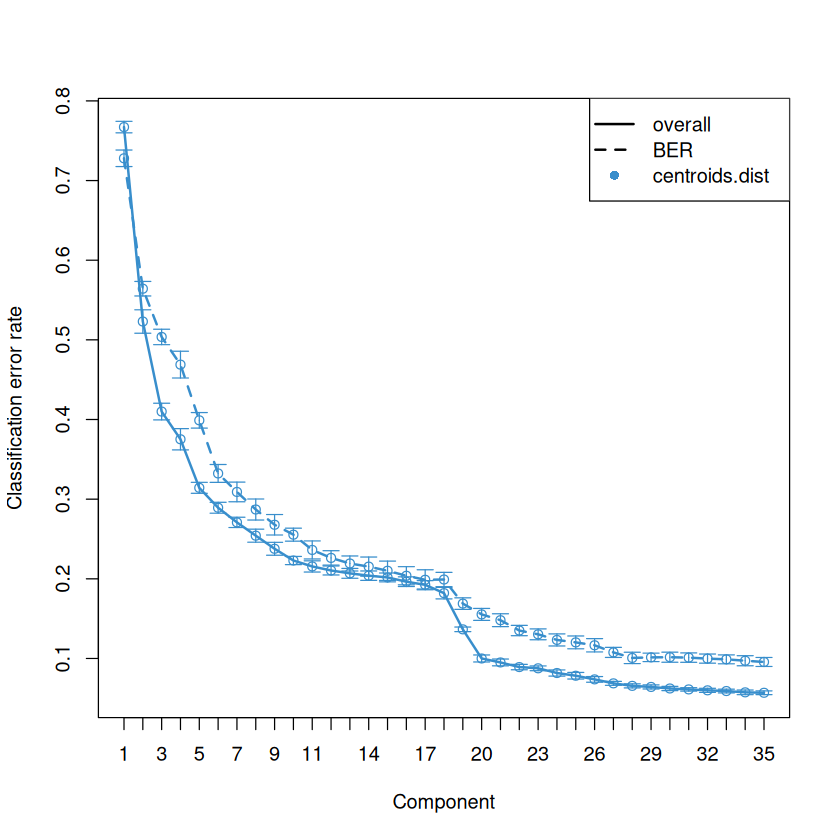

In [32]:
plot(perf.gex, criterion = "BER")

In [33]:
saveRDS(perf.gex, file.path(OUTPUT_DIR, "perf.gex.rds"))

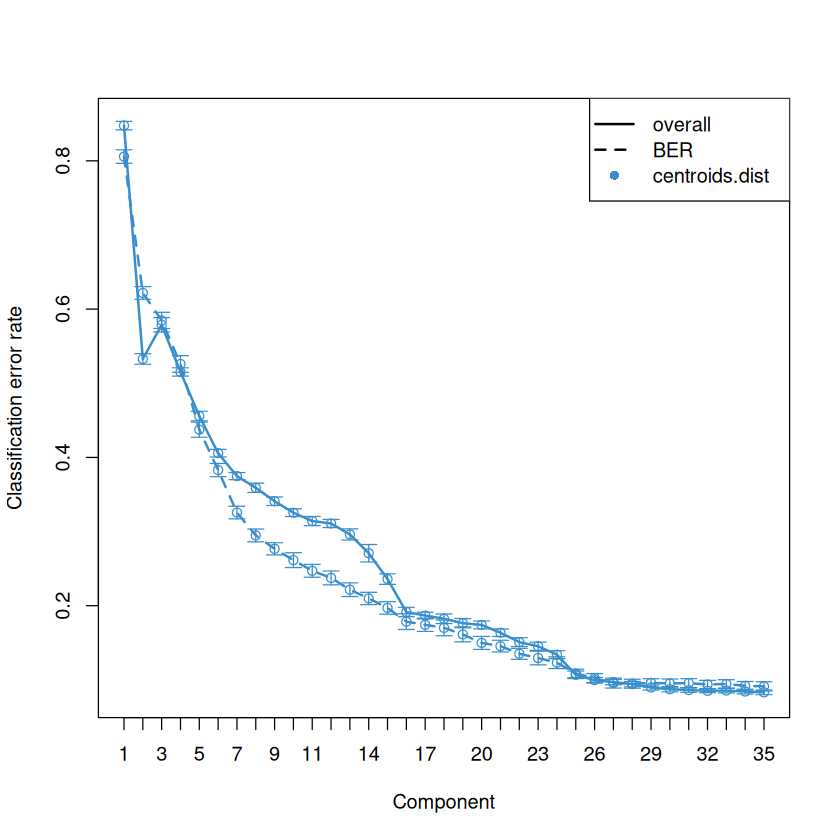

In [34]:

perf.dnam   <- perf(
    model.dnam,
    validation = "Mfold",
    folds = N_FOLDS,
    nrepeat = N_REPEATS,
    light.output = FALSE,
    dist = DIST)
plot(perf.dnam, criterion = "BER")
saveRDS(perf.dnam, file.path(OUTPUT_DIR, "perf.dnam.rds"))


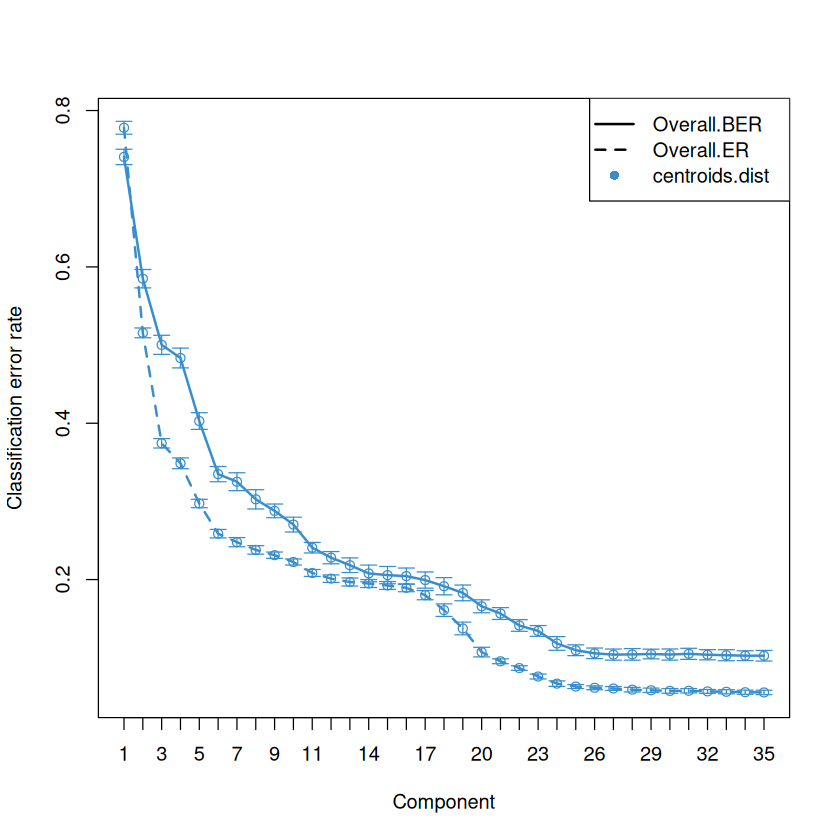

In [11]:
perf.int    <- perf(
    model.integrated,
    validation = "Mfold",
    folds = N_FOLDS,
    nrepeat = N_REPEATS,
    light.output = FALSE,
    dist = DIST)
plot(perf.int, criterion = "BER")
saveRDS(perf.int, file.path(OUTPUT_DIR, "perf.integrated.rds"))